# Document Cleaning and Enhancement using Convolutional Denoising Autoencoders
### Deep Learning Mini-Project

**Problem Statement:** Scanned, archived, and photographed text documents often contain severe noise—such as background bleed-through, paper creases, shadows, and physical stains (e.g. coffee spills)—which degrade visual legibility and cause Optical Character Recognition (OCR) engines to fail.

**Objective:** Build and train an end-to-end **Convolutional Denoising Autoencoder (CDAE)** in PyTorch to filter out complex non-text noise patterns while preserving sharp typography and stroke continuity for downstream document analysis.

**Dataset:** Kaggle *Denoising Dirty Documents* dataset (paired synthetic and real degraded scans with corresponding clean ground-truth documents).

## 1. Setup and Environment Verification
Importing PyTorch, torchvision, image processing tools, and verifying GPU acceleration.

In [1]:
!pwd

/kaggle/working


In [2]:
!unzip /kaggle/input/competitions/denoising-dirty-documents/test.zip
!unzip /kaggle/input/competitions/denoising-dirty-documents/train.zip
!unzip /kaggle/input/competitions/denoising-dirty-documents/train_cleaned.zip

Archive:  /kaggle/input/competitions/denoising-dirty-documents/test.zip
   creating: test/
  inflating: test/1.png              
 extracting: test/10.png             
  inflating: test/100.png            
 extracting: test/103.png            
  inflating: test/106.png            
 extracting: test/109.png            
  inflating: test/112.png            
 extracting: test/115.png            
 extracting: test/118.png            
  inflating: test/121.png            
  inflating: test/124.png            
  inflating: test/127.png            
 extracting: test/13.png             
  inflating: test/130.png            
 extracting: test/133.png            
  inflating: test/136.png            
 extracting: test/139.png            
 extracting: test/142.png            
 extracting: test/145.png            
  inflating: test/148.png            
 extracting: test/151.png            
  inflating: test/154.png            
 extracting: test/157.png            
 extracting: test/16.png           

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import os
import math

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: Tesla T4


## 2. Dataset Paths and Hyperparameter Configuration

We train on images at native resolution ($420 \times 540$) to prevent horizontal font compression and aspect ratio distortion.

In [5]:
# dataset directory paths
NOISY_DIR = "/kaggle/working/train"
CLEAN_DIR = "/kaggle/working/train_cleaned"
TEST_DIR  = "/kaggle/working/test"

# local paths for offline execution
# NOISY_DIR = r"D:\DOCS\VIT Ebooks\Fourth Year\Sem 7\DL\DAE\train"
# CLEAN_DIR = r"D:\DOCS\VIT Ebooks\Fourth Year\Sem 7\DL\DAE\train_cleaned"
# TEST_DIR  = r"D:\DOCS\VIT Ebooks\Fourth Year\Sem 7\DL\DAE\test"

# training hyperparameters
IMAGE_WIDTH = 540
IMAGE_HEIGHT = 420
BATCH_SIZE = 8
EPOCHS = 100
LEARNING_RATE = 1e-3
VAL_SPLIT = 0.2  # 80% train, 20% validation split

print(f"Resolution:  {IMAGE_HEIGHT}x{IMAGE_WIDTH}")
print(f"Batch size:  {BATCH_SIZE}")
print(f"Epochs:      {EPOCHS}")
print(f"LR:          {LEARNING_RATE}")


Image size: 420x540
Batch size: 8
Epochs: 100
Learning rate: 0.001


## 3. Data Pipeline & Dataset Definition

We implement a custom `DirtyDocumentDataset` that pairs each degraded document scan with its clean target version. Images are resized to $(420, 540)$ and converted to single-channel grayscale tensors scaled to $[0.0, 1.0]$.

In [6]:
class DirtyDocumentDataset(Dataset):
    """
    Custom dataset for noisy-clean document image pairs.
    
    Each sample returns:
        - noisy_image: tensor [1, H, W] — the dirty/noisy document
        - clean_image: tensor [1, H, W] — the corresponding clean version
    """
    def __init__(self, noisy_dir, clean_dir, transform=None):
        self.noisy_dir = noisy_dir
        self.clean_dir = clean_dir
        self.filenames = sorted(os.listdir(noisy_dir))
        self.transform = transform
        
    def __len__(self):
        return len(self.filenames)
    
    def __getitem__(self, idx):
        name = self.filenames[idx]
        
        # Load as grayscale
        noisy = Image.open(os.path.join(self.noisy_dir, name)).convert("L")
        clean = Image.open(os.path.join(self.clean_dir, name)).convert("L")
        
        if self.transform:
            noisy = self.transform(noisy)
            clean = self.transform(clean)
            
        return noisy, clean


# Define transforms
transform = transforms.Compose([
    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),
    transforms.ToTensor(),  # Converts to [0, 1] range
])

# Create dataset
full_dataset = DirtyDocumentDataset(NOISY_DIR, CLEAN_DIR, transform=transform)

# Train/validation split
val_size = int(len(full_dataset) * VAL_SPLIT)
train_size = len(full_dataset) - val_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

# Create dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Total samples: {len(full_dataset)}")
print(f"Training samples: {train_size}")
print(f"Validation samples: {val_size}")
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Total samples: 144
Training samples: 116
Validation samples: 28
Training batches: 15
Validation batches: 4


### 3.1 Training Sample Verification
Visualizing paired noisy input documents and ground-truth clean targets from the training set.

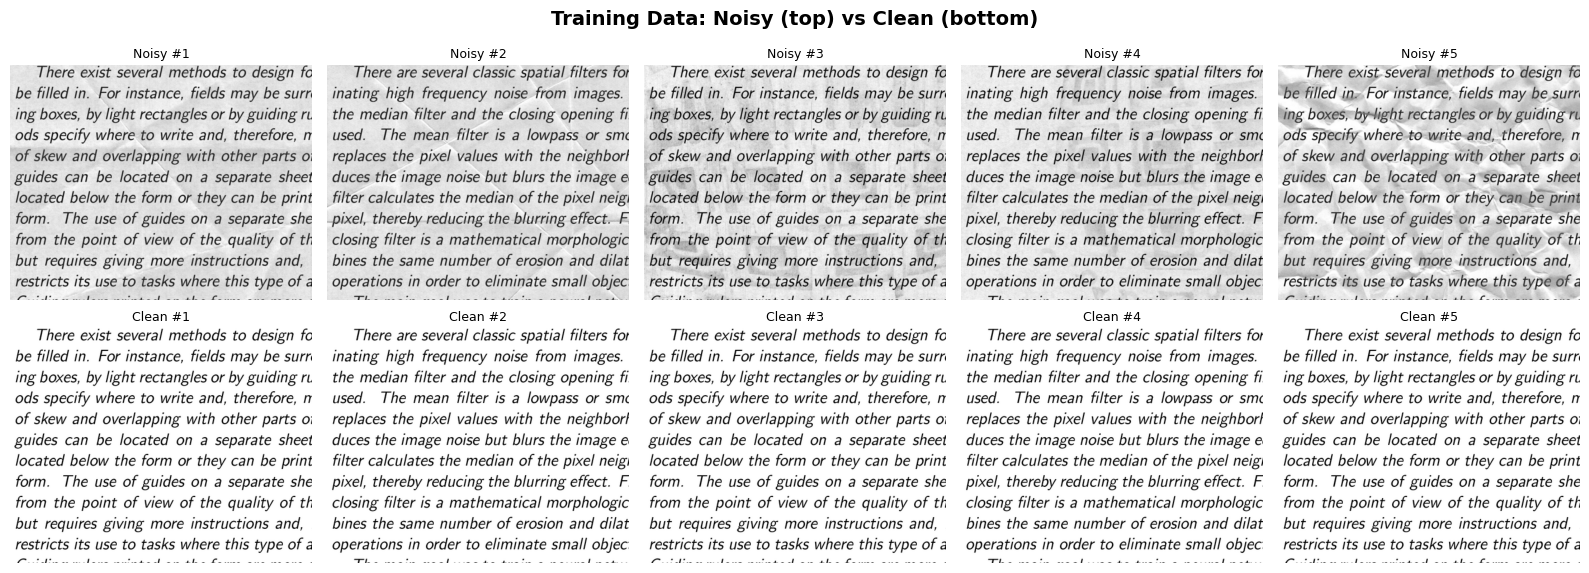

In [7]:
# Visualize a few training pairs
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
fig.suptitle("Training Data: Noisy (top) vs Clean (bottom)", fontsize=14, fontweight='bold')

for i in range(5):
    noisy, clean = full_dataset[i]
    
    axes[0, i].imshow(noisy.squeeze(), cmap='gray')
    axes[0, i].set_title(f'Noisy #{i+1}', fontsize=9)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(clean.squeeze(), cmap='gray')
    axes[1, i].set_title(f'Clean #{i+1}', fontsize=9)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('data_samples.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Convolutional Autoencoder Architecture

Rather than using standard 3-stage downsampling (which compresses dimensions by $8\times$ and destroys fine letter strokes), we design a **2-stage Fully Convolutional Autoencoder**:

1. **Encoder (4x spatial compression):** Two convolutional stages with $3\times 3$ kernels, BatchNorm, ReLU, and $2\times 2$ MaxPool. Because $420 \div 4 = 105$ and $540 \div 4 = 135$, dimensions divide cleanly without fractional loss.
2. **Spatial Latent Representation:** We retain a convolutional bottleneck of shape `[64, 105, 135]`. This preserves spatial 2D relationships and avoids the massive parameter explosion of flattening to a 1D dense layer.
3. **Decoder (Upsample + Convolution):** Instead of `ConvTranspose2d` (which frequently produces checkerboard artifacts), we use nearest-neighbor `nn.Upsample` followed by standard `Conv2d` layers to smoothly reconstruct clean text.
4. **Output Layer:** Sigmoid activation to ensure pixel intensities remain bounded in $[0.0, 1.0]$.

In [12]:
class DenoisingAutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # --- ENCODER ---
        # 2 downsampling stages (4x spatial reduction)
        self.encoder = nn.Sequential(
            # block 1: 1 -> 32 channels, H/2 x W/2
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # block 2: 32 -> 64 channels, H/4 x W/4 (latent bottleneck)
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        
        # --- DECODER ---
        # interpolation upsampling + standard conv to eliminate checkerboard patterns
        self.decoder = nn.Sequential(
            # upsample stage 1: H/4 x W/4 -> H/2 x W/2
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(64, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),
            
            # upsample stage 2: H/2 x W/2 -> H x W
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(32, 1, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid(),
        )
    
    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed


# instantiate model
model = DenoisingAutoEncoder().to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# verify forward pass with dummy tensor
dummy = torch.randn(1, 1, IMAGE_HEIGHT, IMAGE_WIDTH).to(device)
out = model(dummy)
print(f"\nInput shape:  {dummy.shape}")
print(f"Output shape: {out.shape}")


DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): Upsample(scale_factor=2.0, mode='nearest')
    (5): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
   

## 5. Model Training & Optimization

We use **Binary Cross-Entropy (`BCELoss`)** as our objective function. Because document denoising separates dark text from white background, BCE heavily penalizes intermediate gray predictions, encouraging sharp, crisp black strokes. We optimize using **Adam** with `ReduceLROnPlateau` scheduling.

In [14]:
# Loss function and optimizer
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Learning rate scheduler (reduces LR when validation loss plateaus)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

# Training history
history = {
    'train_loss': [],
    'val_loss': [],
}

best_val_loss = float('inf')

print(f"Starting training for {EPOCHS} epochs...")
print("=" * 60)

for epoch in range(EPOCHS):
    # --- Training Phase ---
    model.train()
    train_loss = 0.0
    
    for noisy_imgs, clean_imgs in train_loader:
        noisy_imgs = noisy_imgs.to(device)
        clean_imgs = clean_imgs.to(device)
        
        # Forward pass
        outputs = model(noisy_imgs)
        loss = criterion(outputs, clean_imgs)
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * noisy_imgs.size(0)
    
    train_loss /= len(train_loader.dataset)
    
    # --- Validation Phase ---
    model.eval()
    val_loss = 0.0
    
    with torch.no_grad():
        for noisy_imgs, clean_imgs in val_loader:
            noisy_imgs = noisy_imgs.to(device)
            clean_imgs = clean_imgs.to(device)
            
            outputs = model(noisy_imgs)
            loss = criterion(outputs, clean_imgs)
            val_loss += loss.item() * noisy_imgs.size(0)
    
    val_loss /= len(val_loader.dataset)
    
    # Update scheduler
    scheduler.step(val_loss)
    
    # Save history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    
    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), 'model.pth')
        marker = ' ← Best'
    else:
        marker = ''
    
    # Print progress
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:3d}/{EPOCHS}]  "
              f"Train Loss: {train_loss:.6f}  "
              f"Val Loss: {val_loss:.6f}{marker}")

print("=" * 60)
print(f"Training complete! Best validation loss: {best_val_loss:.6f}")


Starting training for 100 epochs...
Epoch [  1/100]  Train Loss: 0.430902  Val Loss: 0.306405 ← Best
Epoch [  5/100]  Train Loss: 0.153938  Val Loss: 0.151511 ← Best
Epoch [ 10/100]  Train Loss: 0.130104  Val Loss: 0.128861 ← Best
Epoch [ 15/100]  Train Loss: 0.120112  Val Loss: 0.120967 ← Best
Epoch [ 20/100]  Train Loss: 0.115553  Val Loss: 0.116340
Epoch [ 25/100]  Train Loss: 0.113174  Val Loss: 0.112394 ← Best
Epoch [ 30/100]  Train Loss: 0.111657  Val Loss: 0.115814
Epoch [ 35/100]  Train Loss: 0.110040  Val Loss: 0.109444 ← Best
Epoch [ 40/100]  Train Loss: 0.109335  Val Loss: 0.109251 ← Best
Epoch [ 45/100]  Train Loss: 0.108596  Val Loss: 0.107782 ← Best
Epoch [ 50/100]  Train Loss: 0.107685  Val Loss: 0.110874
Epoch [ 55/100]  Train Loss: 0.106848  Val Loss: 0.108980
Epoch [ 60/100]  Train Loss: 0.106657  Val Loss: 0.106017 ← Best
Epoch [ 65/100]  Train Loss: 0.106520  Val Loss: 0.105951 ← Best
Epoch [ 70/100]  Train Loss: 0.105819  Val Loss: 0.106030
Epoch [ 75/100]  Train L

## 6. Training and Validation Loss Analysis
Plotting loss trajectories across epochs to verify convergence and monitor for overfitting.

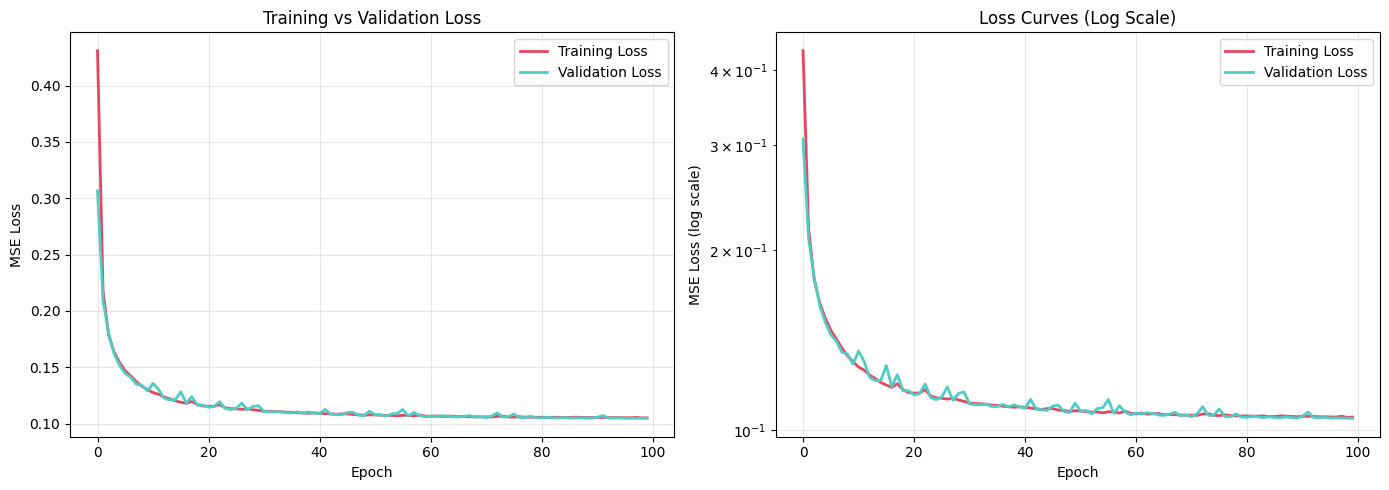

Final train loss: 0.105060
Final val loss:   0.104582
Best val loss:    0.104582


In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Full loss curves
ax1.plot(history['train_loss'], label='Training Loss', color='#e94560', linewidth=2)
ax1.plot(history['val_loss'], label='Validation Loss', color='#4ecdc4', linewidth=2)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('MSE Loss')
ax1.set_title('Training vs Validation Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Loss curves (log scale)
ax2.plot(history['train_loss'], label='Training Loss', color='#e94560', linewidth=2)
ax2.plot(history['val_loss'], label='Validation Loss', color='#4ecdc4', linewidth=2)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('MSE Loss (log scale)')
ax2.set_title('Loss Curves (Log Scale)')
ax2.set_yscale('log')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Final train loss: {history['train_loss'][-1]:.6f}")
print(f"Final val loss:   {history['val_loss'][-1]:.6f}")
print(f"Best val loss:    {best_val_loss:.6f}")

## 7. Qualitative Evaluation on Validation Documents
Visual comparison across validation samples: **Degraded Input** $\rightarrow$ **Model Denoised** $\rightarrow$ **Ground Truth Clean**.

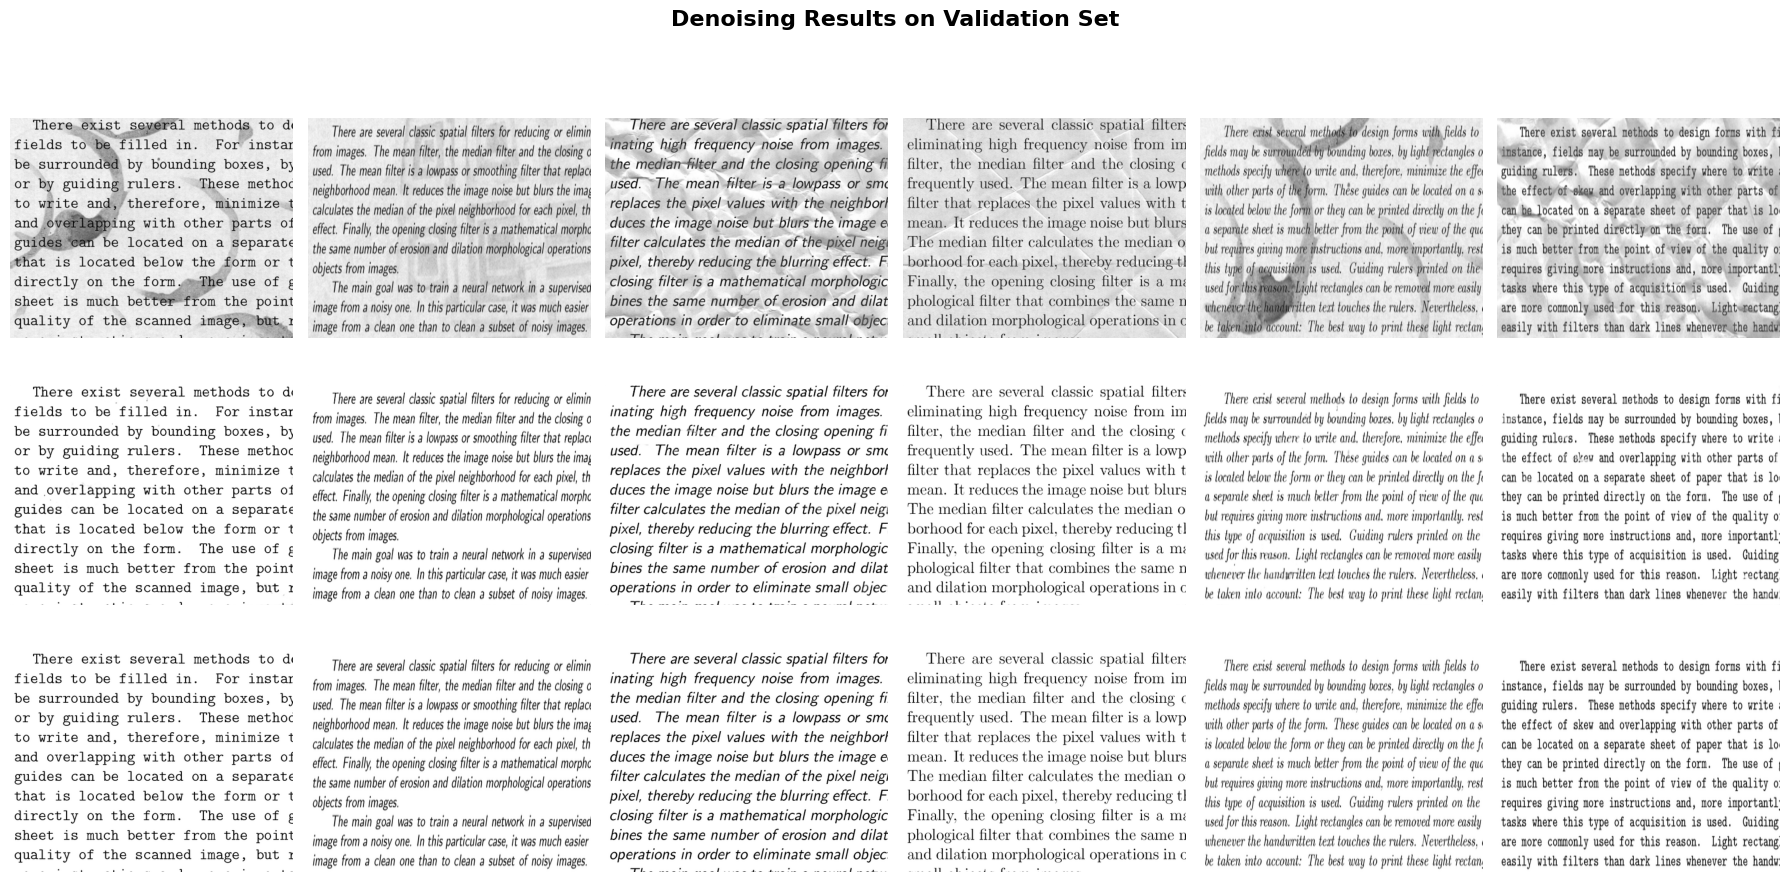

In [16]:
# Load best model
model.load_state_dict(torch.load('model.pth', map_location=device))
model.eval()

# Get validation samples
val_noisy, val_clean = [], []
val_outputs = []

with torch.no_grad():
    for noisy_imgs, clean_imgs in val_loader:
        noisy_imgs = noisy_imgs.to(device)
        outputs = model(noisy_imgs)
        
        val_noisy.extend(noisy_imgs.cpu())
        val_clean.extend(clean_imgs)
        val_outputs.extend(outputs.cpu())

# Plot results (6 samples)
n_samples = min(6, len(val_noisy))
fig, axes = plt.subplots(3, n_samples, figsize=(3 * n_samples, 9))
fig.suptitle('Denoising Results on Validation Set', fontsize=16, fontweight='bold', y=1.02)

row_labels = ['Noisy Input', 'DAE Output', 'Ground Truth']

for i in range(n_samples):
    # Row 1: Noisy input
    axes[0, i].imshow(val_noisy[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_ylabel('Noisy Input', fontsize=12, fontweight='bold')
    
    # Row 2: Model output (denoised)
    axes[1, i].imshow(val_outputs[i].squeeze(), cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_ylabel('DAE Output', fontsize=12, fontweight='bold')
    
    # Row 3: Ground truth (clean)
    axes[2, i].imshow(val_clean[i].squeeze(), cmap='gray')
    axes[2, i].axis('off')
    if i == 0:
        axes[2, i].set_ylabel('Ground Truth', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('visual_results.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Quantitative Evaluation (PSNR and SSIM)

We assess reconstruction quality across two standard metrics:
- **PSNR (Peak Signal-to-Noise Ratio):** Measures logarithmic ratio between peak signal and reconstruction error (higher is better, $>20\text{ dB}$ indicates strong restoration).
- **SSIM (Structural Similarity Index):** Evaluates structural, luminance, and contrast consistency (closer to $1.0$ is better).

In [17]:
def compute_psnr(img1, img2, max_val=1.0):
    """Compute Peak Signal-to-Noise Ratio between two images."""
    mse = torch.mean((img1 - img2) ** 2).item()
    if mse == 0:
        return float('inf')
    return 10 * math.log10((max_val ** 2) / mse)


def compute_ssim(img1, img2, window_size=11, C1=0.01**2, C2=0.03**2):
    """
    Compute Structural Similarity Index between two images.
    Simplified version for grayscale images.
    """
    mu1 = img1.mean()
    mu2 = img2.mean()
    sigma1_sq = img1.var()
    sigma2_sq = img2.var()
    sigma12 = ((img1 - mu1) * (img2 - mu2)).mean()
    
    ssim = ((2 * mu1 * mu2 + C1) * (2 * sigma12 + C2)) / \
           ((mu1**2 + mu2**2 + C1) * (sigma1_sq + sigma2_sq + C2))
    return ssim.item()


# Compute metrics on validation set
psnr_noisy_list = []   # PSNR between noisy input and clean (baseline)
psnr_denoised_list = []  # PSNR between denoised output and clean
ssim_noisy_list = []
ssim_denoised_list = []

for i in range(len(val_noisy)):
    noisy = val_noisy[i].squeeze()
    clean = val_clean[i].squeeze()
    denoised = val_outputs[i].squeeze()
    
    # PSNR
    psnr_noisy_list.append(compute_psnr(noisy, clean))
    psnr_denoised_list.append(compute_psnr(denoised, clean))
    
    # SSIM
    ssim_noisy_list.append(compute_ssim(noisy, clean))
    ssim_denoised_list.append(compute_ssim(denoised, clean))

# Print results
print("=" * 60)
print("EVALUATION METRICS (Validation Set)")
print("=" * 60)
print(f"\n{'Metric':<25} {'Noisy→Clean':<18} {'Denoised→Clean':<18} {'Improvement'}")
print("-" * 75)
print(f"{'PSNR (dB) ↑':<25} {np.mean(psnr_noisy_list):<18.2f} {np.mean(psnr_denoised_list):<18.2f} {np.mean(psnr_denoised_list) - np.mean(psnr_noisy_list):+.2f} dB")
print(f"{'SSIM ↑':<25} {np.mean(ssim_noisy_list):<18.4f} {np.mean(ssim_denoised_list):<18.4f} {np.mean(ssim_denoised_list) - np.mean(ssim_noisy_list):+.4f}")
print(f"\n✅ Higher PSNR = better reconstruction (>20dB is good)")
print(f"✅ SSIM closer to 1.0 = more structurally similar")

EVALUATION METRICS (Validation Set)

Metric                    Noisy→Clean        Denoised→Clean     Improvement
---------------------------------------------------------------------------
PSNR (dB) ↑               16.27              25.45              +9.18 dB
SSIM ↑                    0.9134             0.9777             +0.0643

✅ Higher PSNR = better reconstruction (>20dB is good)
✅ SSIM closer to 1.0 = more structurally similar


## 9. Inference on Unseen Test Dataset
Evaluating the trained autoencoder on competition test images containing real-world scanning defects.

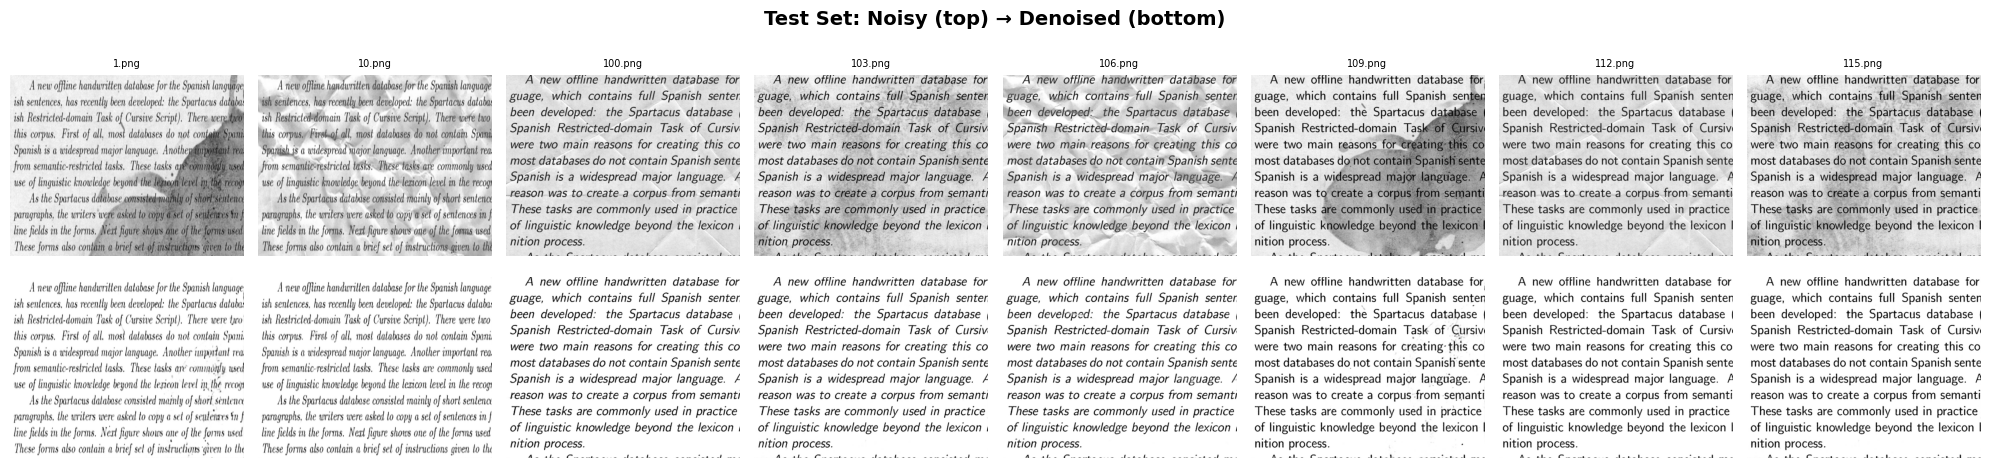


✅ Processed 72 test images


In [18]:
# Test set inference
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),
    transforms.ToTensor(),
])

test_files = sorted(os.listdir(TEST_DIR))
test_noisy = []
test_denoised = []

model.eval()
with torch.no_grad():
    for fname in test_files:
        img = Image.open(os.path.join(TEST_DIR, fname)).convert("L")
        tensor = test_transform(img).unsqueeze(0).to(device)
        output = model(tensor)
        
        test_noisy.append(tensor.cpu().squeeze())
        test_denoised.append(output.cpu().squeeze())

# Visualize 8 test samples
n_show = min(8, len(test_noisy))
fig, axes = plt.subplots(2, n_show, figsize=(2.5 * n_show, 5))
fig.suptitle('Test Set: Noisy (top) → Denoised (bottom)', fontsize=14, fontweight='bold')

for i in range(n_show):
    axes[0, i].imshow(test_noisy[i], cmap='gray')
    axes[0, i].set_title(test_files[i], fontsize=7)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(test_denoised[i], cmap='gray')
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('test_results.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Processed {len(test_files)} test images")

## 10. Model Checkpoint Export
Saving the trained model weights for offline inference.

In [19]:
# save final model checkpoint
save_path = 'model.pth'
model_size = os.path.getsize(save_path) / (1024 * 1024)

print(f"Model saved: {save_path}")
print(f"File size:   {model_size:.2f} MB")
print(f"Parameters:  {total_params:,}")


📦 Model saved: model.pth
📏 Model size: 0.15 MB
🔢 Parameters: 37,825

To use in the web demo:
  1. Download model.pth from Kaggle output
  2. Place it in the DAE/ project folder
  3. Run: python app.py
  4. Open: http://localhost:5000
